In [55]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Завдання 1. Побудова вибірки денних температур (Київ, липень = 20°C)
np.random.seed(1)
daily_temps = np.random.normal(loc=20.0, scale=2.5, size=30)

print("Згенерована вибірка денних температур:\n", daily_temps)
print("\nВибіркове середнє (mean):", daily_temps.mean())
print("Вибіркове стандартне відхилення (std):", daily_temps.std(ddof=1))

Згенерована вибірка денних температур:
 [24.06086341 18.47060897 18.67957062 17.31757844 22.16351907 14.24615326
 24.36202941 18.09698275 20.79759774 19.37657406 23.65526984 14.84964823
 19.19395699 19.03986411 22.83442361 17.25027183 19.56892948 17.80535396
 20.10553437 21.45703803 17.24845206 22.86180927 22.2539768  21.25623585
 22.25213987 18.29068035 19.69277444 17.66057641 19.3302798  21.32588867]

Вибіркове середнє (mean): 19.850152723360946
Вибіркове стандартне відхилення (std): 2.5659128773681417


In [56]:
# Завдання 2. Параметри нормального розподілу
mean_val = daily_temps.mean()
std_val = daily_temps.std(ddof=1)

# Створення об'єкта теоретичного розподілу
dist = stats.norm(loc=mean_val, scale=std_val)
print(f"Підібрана нормальна модель: N(μ = {mean_val:.2f}, σ = {std_val:.2f})")

Підібрана нормальна модель: N(μ = 19.85, σ = 2.57)


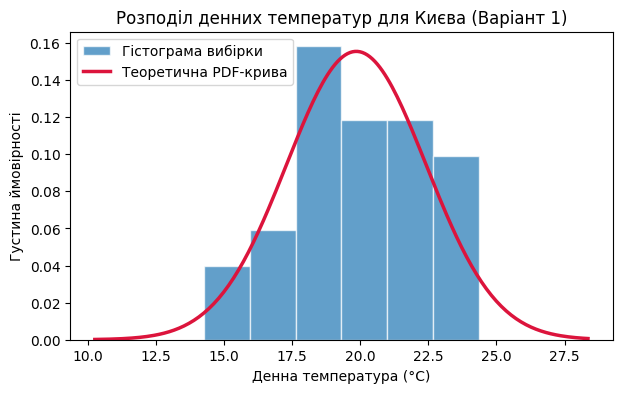

In [57]:
# Завдання 3. Гістограма і теоретична pdf-крива
fig, ax = plt.subplots(figsize=(7, 4))

# Гістограма реальних даних (density=True обов'язковий для порівняння з pdf)
ax.hist(daily_temps, bins=6, density=True, edgecolor="white", alpha=0.7, label="Гістограма вибірки")

# Теоретична крива густини ймовірності (PDF)
x = np.linspace(daily_temps.min() - 4, daily_temps.max() + 4, 200)
ax.plot(x, dist.pdf(x), color="crimson", linewidth=2.5, label="Теоретична PDF-крива")

ax.set_xlabel("Денна температура (°C)")
ax.set_ylabel("Густина ймовірності")
ax.set_title("Розподіл денних температур для Києва (Варіант 1)")
ax.legend()
plt.show()

In [58]:
# Завдання 4. Ймовірність потрапляння в інтервал [μ - σ, μ + σ]
lower_bound = mean_val - std_val
upper_bound = mean_val + std_val

prob = dist.cdf(upper_bound) - dist.cdf(lower_bound)
print(f"Ймовірність у межах [mean - std, mean + std]: {prob:.4f} ({prob * 100:.1f}%)")

Ймовірність у межах [mean - std, mean + std]: 0.6827 (68.3%)


In [59]:
# Завдання 5. Пошук 95-го процентиля через .ppf()
p95 = dist.ppf(0.95)
print(f"Температура 95-го процентиля: {p95:.2f}°C")

Температура 95-го процентиля: 24.07°C


### Відповіді на контрольні запитання:

1. **Різниця між .pdf(x) та .cdf(x):**
   - `.pdf(x)` (Probability Density Function) повертає *густину ймовірності* в конкретній точці $x$ (висоту кривої у дзвоноподібному розподілі).
   - `.cdf(x)` (Cumulative Distribution Function) повертає *накопичену ймовірність* (сумарну частку спостережень), яка лежить ліворуч від заданого значення $x$ (тобто ймовірність того, що випадкова величина буде меншою або рівною за $x$).

2. **Чому значення .pdf(x) може бути більшим за 1 і чому це не суперечить теорії:**
   - Для неперервних випадкових величин `.pdf(x)` є не ймовірністю події у точці (яка дорівнює нулю), а *густиною*. Густина може перевищувати одиницю, якщо площа під кривою в обмеженому інтервалі залишається рівною 1, а сама крива дуже вузька та висока. Головна умова нормального розподілу — інтеграл (площа) під усім графіком PDF дорівнює рівно 1, а не висота окремих точок.

3. **Чому .ppf() є оберненою до .cdf():**
   - Вони виконують симетричні взаємно обернені операції: `.cdf(x)` приймає на вхід *значення* випадкової величини, а на вихід дає *накопичену ймовірність* (частку); натомість `.ppf(q)` приймає на вхід *накопичену ймовірність* (квантиль $q$), а на вихід дає відповідне їй *значення* випадкової величини.